# TDCS: denser temporal and spectral context

## tl;dr

This round **improved** on the retained **0.3800** TDCS blend.
Selected method: **retained_dense_equal**. Pooled native-row TDCS
OOF mAP: **0.3877**, change
**+0.0077**. Recorded decision: **retain new TDCS candidate**.

Saved predictions passed an independent rank-based AP calculation on all
6,959,762 native rows. DeFOG's reported **0.817** remains untouched. No Kaggle
leaderboard scoring or competition submission occurs in this experiment.

These are exploratory development results. The same subject folds have been
reused for architecture selection, so the selected gain may be optimistic.

## Context & Methods

Extend the sensor HGB model with **112 additional features**: 72 spectral
features plus 40 shifted temporal-context features. Training stride changes
from 32 to 16 native rows (0.25 to 0.125 seconds at 128 Hz). The original 101
sensor features are retained, giving 213 features in total.

Spectral features use centered 2- and 8-second Hann windows of each normalized
accelerometer axis and an orientation-invariant dynamic-magnitude channel.
On the 0.5–15 Hz spectrum they measure power, normalized entropy, centroid,
spread, dominant frequency, peak concentration, and three relative band
powers. Context features shift local means, variation, and band ratios by
±0.5 and ±2 seconds, clamping at each recording's boundary.

Three independent histogram gradient boosting classifiers use 260 iterations,
learning rate 0.07, 31 leaves, at least 200 samples per leaf, and L2
regularization 20. Positive weights use training labels only, with square-root
negative/positive ratio capped at 8. No early stopping uses held-out labels.
Settings and the three blend definitions were saved before evaluation.

References for implementation APIs:
[NumPy real FFT](https://numpy.org/doc/stable/reference/generated/numpy.fft.rfft.html)
and [histogram gradient boosting](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.HistGradientBoostingClassifier.html).

### Key Assumptions

- Same 815 recordings, 61 subjects, and five frozen subject-disjoint folds;
  public-example subject `4dc2f8` remains excluded. Subject IDs are not features.
- Labels, event intervals, task labels, and clinical metadata are not inputs.
- Centered spectra, past/future context, and whole-record normalization assume
  offline detection, not a causal real-time detector.
- AP is pooled over **all native rows** per target; mAP is the mean of those
  three APs. Fold averages are not this pooled metric.
- This joint feature/density/model change does not isolate which component
  causes an improvement. Candidate selection reuses development folds;
  independent generalization needs fresh subjects or fully nested retraining.

## Data

This notebook is a completed experiment log. It reads preserved artifacts and
regenerates figures; it does not call a scoring endpoint. Rebuild training from
the project root with the companion script:

```powershell
.\.venv\Scripts\python.exe -u scripts/tdcs_dense_context_experiment.py
```

Inputs: `data/raw/train/tdcsfog`, the verified sensor manifest/cache under
`results/tdcs_multiscale_signal`, and neural OOF predictions under
`kaggle-output/fog-evidence-weighted/competition/neural/tdcsfog`. The companion
verifies the neural OOF fold/recording mapping. Outputs are separate under
`results/tdcs_dense_context/<fingerprint>`; previous experiments are preserved.

### Load completed results and preserved provenance

In [1]:
import json
import sys
from pathlib import Path
import pandas as pd
from IPython.display import display, Image

candidates = [Path.cwd(), *Path.cwd().parents, Path('D:/Dissertation')]
PROJECT_ROOT = next(path for path in candidates if
                    (path / 'scripts' / 'tdcs_dense_context_experiment.py').exists())
sys.path.insert(0, str(PROJECT_ROOT / 'scripts'))
import tdcs_dense_context_experiment as experiment
decision = json.loads((PROJECT_ROOT / 'results' / 'tdcs_dense_context' / 'latest_run.json').read_text())
run_dir = Path(decision['run_dir'])
metrics = pd.read_csv(run_dir / 'candidate_metrics.csv')
fold_metrics = pd.read_csv(run_dir / 'candidate_fold_metrics.csv')
audit = json.loads((run_dir / 'audit.json').read_text())
configuration = json.loads((run_dir / 'predeclared_configuration.json').read_text())
validation = json.loads((Path(decision['selected_candidate_dir']) / 'validation.json').read_text())
print('Preserved run:', run_dir)

Preserved run: D:\Dissertation\results\tdcs_dense_context\e1844437c340c0b75d39


### Reconcile saved results with the independent validation

In [2]:
selected = metrics.loc[metrics.method.eq(decision['selected_method'])].iloc[0]
assert validation['status'] == 'passed'
assert validation['native_rows'] == audit['native_rows'] == 6959762
assert validation['recordings'] == audit['recordings'] == 815
assert validation['subjects'] == audit['subjects'] == 61
assert validation['subject_disjoint'] and validation['prediction_ids_exact_match']
for target in [*experiment.TARGETS, 'mAP']:
    assert abs(selected[target] - validation['independent_rank_based_AP'][target]) < 1e-10
assert audit['feature_count'] == 213 and audit['training_stride'] == 16
assert not audit['competition_submission_created']
display(pd.DataFrame([{'check': name, 'value': audit[name]} for name in
                     ['recordings', 'subjects', 'native_rows', 'sampled_training_rows',
                      'feature_count', 'training_stride', 'validation']]))
print('Independent native-row AP: passed. Development-fold reuse remains a limitation.')

Independent native-row AP: passed. Development-fold reuse remains a limitation.


,check,value
0,recordings,815
1,subjects,61
2,native_rows,6959762
3,sampled_training_rows,436128
4,feature_count,213
5,training_stride,16
6,validation,same five frozen subject-disjoint folds; outer...


### Inspect the fixed model settings and blends

In [3]:
display(pd.DataFrame([{'parameter': name, 'value': value} for name, value in
                     configuration['model_parameters'].items()]))
display(pd.DataFrame(configuration['fixed_blends']).fillna(0).T)

,parameter,value
0,learning_rate,0.07
1,max_iter,260
2,max_leaf_nodes,31
3,min_samples_leaf,200
4,l2_regularization,20.0
5,max_bins,128
6,early_stopping,False


,previous_tdcs_blend,dense_context_hgb,retained_neural_hgb
neural_dense_equal,0.5,0.50,0.00
retained_dense_quarter,0.0,0.25,0.75
retained_dense_equal,0.0,0.50,0.50


## Results

### Compare every candidate, including the retained reference

In [4]:
display(metrics.sort_values('mAP', ascending=False).style.format(
    {name: '{:.4f}' for name in [*experiment.TARGETS, 'mAP']}))
figures = experiment.make_figures(metrics, run_dir)

,method,StartHesitation,Turn,Walking,mAP
4,retained_dense_equal,0.1905,0.7886,0.1839,0.3877
3,retained_dense_quarter,0.1871,0.7862,0.1820,0.3851
1,dense_context_hgb,0.2104,0.7830,0.1596,0.3843
2,neural_dense_equal,0.1904,0.7782,0.1723,0.3803
0,retained_neural_hgb,0.1848,0.7808,0.1744,0.3800


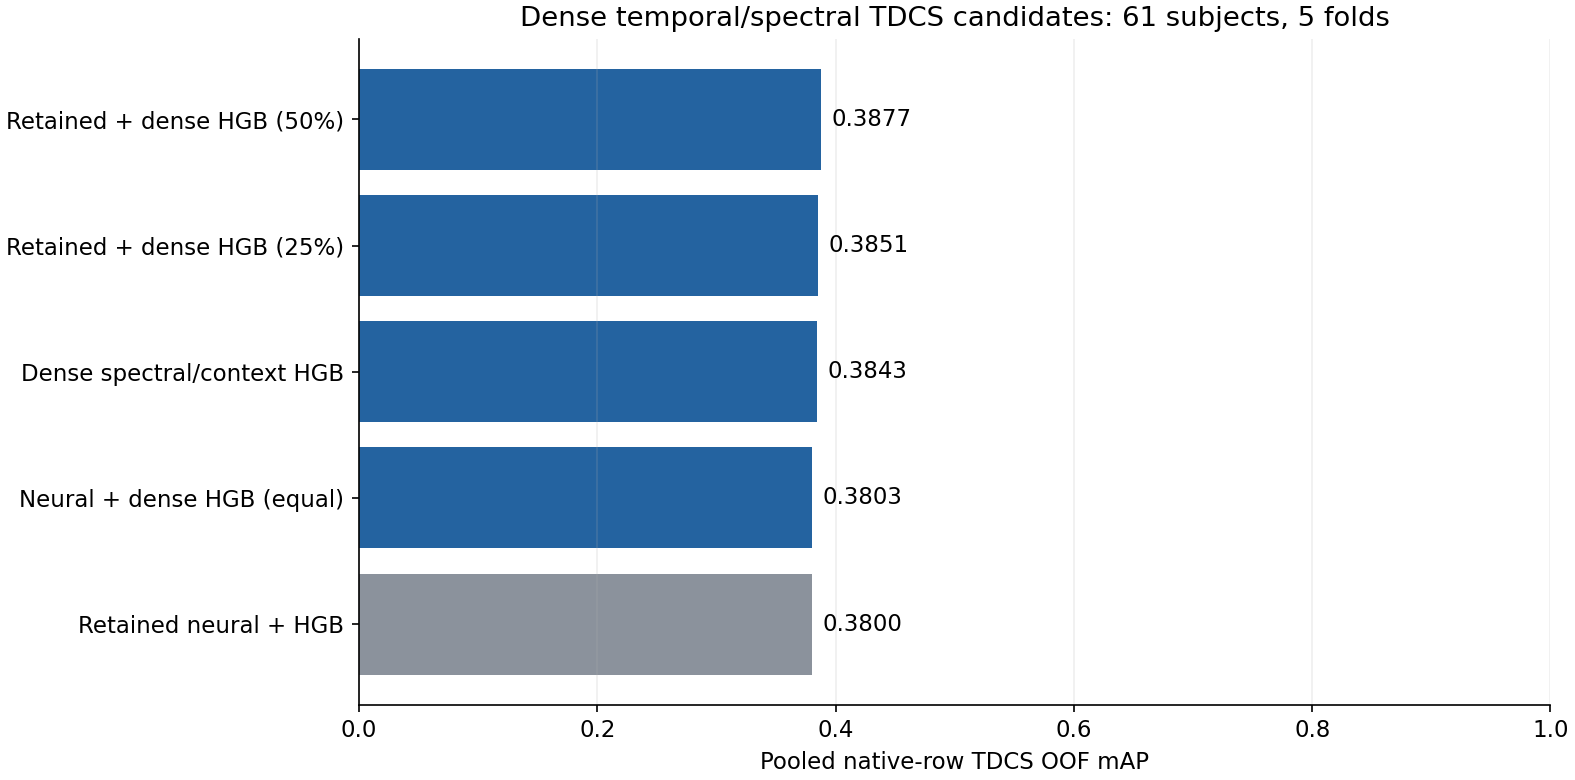

In [5]:
display(Image(filename=str(figures[0])))

### Inspect class tradeoffs

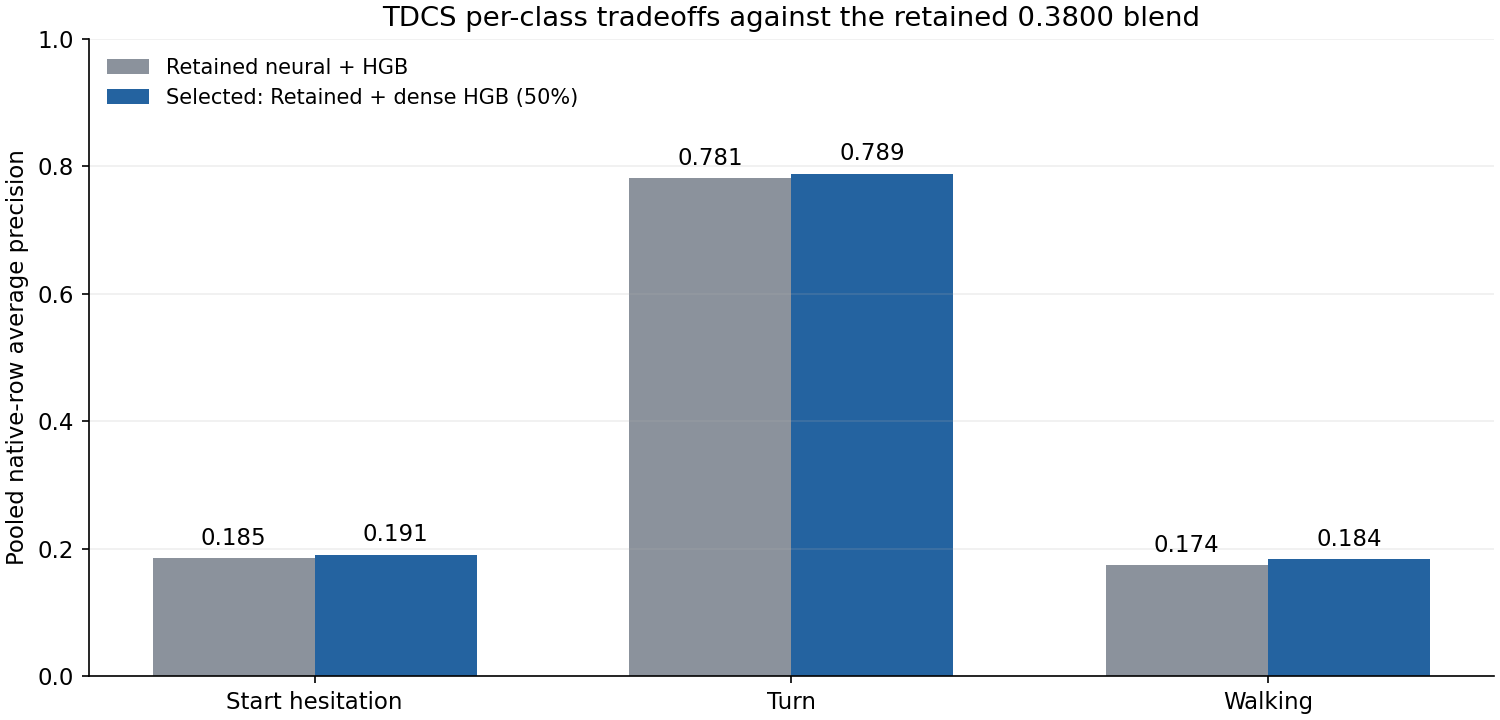

In [6]:
display(Image(filename=str(figures[1])))

### Inspect held-out subject-fold variation

Fold variation is descriptive, not a confidence interval. Compare pooled
native-row mAP above for the primary decision.

In [7]:
display(fold_metrics.loc[fold_metrics.method.eq(decision['selected_method'])].style.format(
    {name: '{:.4f}' for name in [*experiment.TARGETS, 'mAP']}))

,method,fold,StartHesitation,Turn,Walking,mAP
20,retained_dense_equal,0,0.3934,0.8382,0.2079,0.4799
21,retained_dense_equal,1,0.1086,0.7928,0.2207,0.3741
22,retained_dense_equal,2,0.1563,0.7166,0.0543,0.3090
23,retained_dense_equal,3,0.0657,0.8495,0.0808,0.3320
24,retained_dense_equal,4,0.0645,0.8259,0.0609,0.3171


## Takeaways

Retain a new candidate only when its pooled mAP exceeds the previous reference;
otherwise preserve the previous 0.3800 blend. Keep the per-class tradeoffs and
failed candidates visible. No model-selection result here establishes an
independent generalization gain, and DeFOG is not retrained or overwritten.

In [8]:
print('Decision:', decision['decision'])
print(f"TDCS pooled native-row OOF mAP: {decision['candidate_tdcs_oof_map']:.4f}")
print(f"Change from retained reference: {decision['delta']:+.4f}")
print('DeFOG reported 0.817 preserved; no competition scoring or submission.')
print('Reused subject folds: exploratory model selection, not independent validation.')

Decision: retain new TDCS candidate
TDCS pooled native-row OOF mAP: 0.3877
Change from retained reference: +0.0077
DeFOG reported 0.817 preserved; no competition scoring or submission.
Reused subject folds: exploratory model selection, not independent validation.
